# Ionic models: charged species and the two-sublattice ionic liquid

Oxides and ionic melts are described with charged species. Two models are
supported:

- **Charged CEF phases**, such as fluorite (Nd³⁺, Zr⁴⁺)₂(O²⁻, Va)₄. A
  configuration is physical only if it is neutral, Σ_s a_s Σ_c q_c y_s,c = 0.
  That is an equality on the site fractions, added to the restricted solve,
  to every pricing problem, and to the interval bounds (a box whose charge
  interval excludes 0 is dropped). With fixed valences, one neutrality or
  element-balance row is redundant, and the solve leaves it out.
- **The two-sublattice ionic liquid** (Sundman 1991), (C^{+v})_P (A^{−v}, Va,
  B⁰)_Q. Its site ratios follow from neutrality: Q is the average cation
  charge, and P the anion charge plus Q times the vacancy fraction. So the
  number of atoms per formula unit depends on y, and one phase spans a metal
  (cations on vacancies) and an oxide melt.

References for comparison:

- B. Sundman, *Modification of the two-sublattice model for liquids*, Calphad
  15 (1991) 109–119;
- L. Schramm, G. Behr, W. Löser and K. Wetzig, *Thermodynamic reassessment of
  the Cu–O phase diagram*, J. Phase Equilib. Diffus. 26 (2005) 605–612: the
  Cu–O database;
- E. Shishin and S. A. Decterov, *Critical assessment and thermodynamic
  modeling of the Cu–O and Cu–O–S systems*, Calphad 38 (2012) 59–70: an
  independent assessment of the same data;
- O. Fabrichnaya and H. J. Seifert, *Assessment of thermodynamic functions in
  the ZrO₂–Nd₂O₃–Al₂O₃ system*, Calphad 32 (2008) 142–151.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pycalphad
from scipy.optimize import brentq

from discopt.calphad import ThermoDatabase, databases, equilibrium
from discopt.calphad.equilibrium.common import R_GAS
from discopt.calphad.ops import NUM
from discopt.calphad.plot import plot_gx

db = databases.load("cuo_schramm")
models = db.phase_models(("CU", "O"))
phases = list(models.values())
liq = models["IONIC_LIQ"]
print("phases:", sorted(models))
print("liquid:", liq.constituents)

phases: ['CU2O', 'CUO', 'FCC_A1', 'GAS', 'IONIC_LIQ']
liquid: (('CU+1', 'CU+2', 'CU+3'), ('O-2', 'VA'))


## Site ratios follow from neutrality

Along the liquid from metallic Cu (Cu⁺:Va) to the Cu₂O melt (Cu⁺:O²⁻), Q = 1
(all Cu⁺) and P = 2 y_O + y_Va. The formula unit holds P Cu and Q y_O O, so
x(O) runs from 0 to 1/3:

In [2]:
for y_o in (0.0, 0.25, 0.5, 0.75, 1.0):
    Y = [{"CU+1": 1.0, "CU+2": 0.0, "CU+3": 0.0}, {"O-2": y_o, "VA": 1 - y_o}]
    P, Q = liq.ratios(Y)
    print(f"y(O-2) = {y_o:4.2f}: P = {P:.2f}, Q = {Q:.2f}, x(O) = {Q * y_o / (P + Q * y_o):.3f}")

y(O-2) = 0.00: P = 1.00, Q = 1.00, x(O) = 0.000
y(O-2) = 0.25: P = 1.25, Q = 1.00, x(O) = 0.167
y(O-2) = 0.50: P = 1.50, Q = 1.00, x(O) = 0.250
y(O-2) = 0.75: P = 1.75, Q = 1.00, x(O) = 0.300
y(O-2) = 1.00: P = 2.00, Q = 1.00, x(O) = 0.333


## The liquid miscibility gap at 1500 K

At 1500 K the metal-rich and oxide-rich liquids are one phase with two minima.
Pricing finds the second one as a new composition set of the same phase:

STABILITY_SEARCHED after 2 iteration(s); T = 1500 K; eps = 1e-05 RT
  mu/RT = [ -6.7583706  -18.37878942]   G/RT = -9.0824543651
  IONIC_LIQ: x = [0.6916154 0.3083846]  amount = 0.19283370
  IONIC_LIQ: x = [0.90543392 0.09456608]  amount = 0.40967699
  pricing GAS: LB = 9.001e+00  UB = 9.001e+00
  pricing IONIC_LIQ: LB = none  UB = 1.971e-09
  pricing FCC_A1: LB = none  UB = 1.772e-01
  pricing CU2O: LB = 1.004e-02  UB = 1.004e-02
  pricing CUO: LB = 2.531e+00  UB = 2.531e+00
  note: local pricing only, so no global lower bounds: call res.certify() to certify


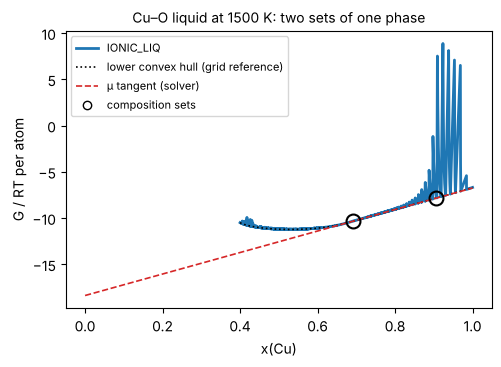

In [3]:
res = equilibrium(phases, x=0.8, T=1500.0, certify="none")  # x is x(Cu)
print(res.summary())
fig, ax = plt.subplots(figsize=(5.5, 3.6))
plot_gx([liq], res, T=1500.0, ax=ax)
ax.set_xlabel("x(Cu)")
ax.set_title("Cu–O liquid at 1500 K: two sets of one phase", fontsize=10)
plt.show()

pycalphad, on the same database, misses the gap at these compositions and
returns liquid + Cu₂O, which is higher in G than the two liquids found here:

In [4]:
from pycalphad import Database  # noqa: E402
from pycalphad import equilibrium as peq  # noqa: E402
from pycalphad import variables as v  # noqa: E402

pdb = Database(str(databases.fetch("cuo_schramm")))
for xo in (0.2, 0.25, 0.3):
    r = equilibrium(phases, x=1 - xo, T=1500.0, certify="none")
    eq = peq(pdb, ["CU", "O", "VA"], sorted(models), {v.X("O"): xo, v.T: 1500.0, v.P: 101325, v.N: 1})
    ref_sets = [str(n) for n in np.squeeze(eq.Phase.values) if n]
    g_ref = float(np.squeeze(eq.GM.values))
    g_ours = r.G * R_GAS * 1500.0
    print(
        f"x(O) = {xo}: ours {[cs.phase.name for cs in r.composition_sets]} G = {g_ours:.1f};  "
        f"pycalphad {ref_sets} G = {g_ref:.1f} J/mol"
    )

/home/user/discopt-calphad/.venv/lib/python3.12/site-packages/pycalphad/io/tdb.py:1017: UserWarning: The type definition character `'` was defined in the following phases: ['FCC_A1'], but no corresponding TYPE_DEFINITION line was found in the TDB.
  warnings.warn(f"The type definition character `{typechar}` was defined in the following phases: "


x(O) = 0.2: ours ['IONIC_LIQ', 'IONIC_LIQ'] G = -113273.6;  pycalphad ['IONIC_LIQ', 'CU2O'] G = -113227.6 J/mol


x(O) = 0.25: ours ['IONIC_LIQ', 'IONIC_LIQ'] G = -120519.9;  pycalphad ['IONIC_LIQ', 'CU2O'] G = -120475.5 J/mol


x(O) = 0.3: ours ['IONIC_LIQ', 'IONIC_LIQ'] G = -127766.2;  pycalphad ['IONIC_LIQ', 'CU2O'] G = -127723.4 J/mol


Local pricing (`certify="none"`) is a heuristic, though. At x(O) = 0.15 it
stops at liquid + Cu₂O. The global step (`res.certify()`, or the default
`certify="final"`) finds the second liquid there, 9 J/mol lower. It takes about
12 minutes and ends `GLOBAL_SEARCH_INCOMPLETE`, because the liquid is active
(see below). Only the global bound distinguishes the two cases.

## Invariants

- **eutectic** L → FCC (Cu) + Cu₂O, by bisection on whether liquid is present at
  x(O) = 0.005;
- **monotectic** L₂ → L₁ + Cu₂O: the temperature where Cu₂O touches the common
  tangent of the two liquids;
- **critical point** of the liquid gap: the highest T with two liquids.

In [5]:
def names(xo, T):
    r = equilibrium(phases, x=1 - xo, T=T, certify="none")
    return [cs.phase.name for cs in r.composition_sets if cs.amount > 1e-9]


def bisect(test, lo, hi, tol=0.05):
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if test(mid) else (mid, hi)
    return 0.5 * (lo + hi)


t_eut = bisect(lambda T: "IONIC_LIQ" in names(0.005, T), 1300.0, 1400.0)


def cu2o_above_tangent(T):
    r = equilibrium([liq], x=0.8, T=float(T), certify="none")
    cu2o = models["CU2O"]
    return float(cu2o.gibbs([], NUM, T)) - float(r.mu @ np.array(cu2o.amounts([])))


t_mono = brentq(cu2o_above_tangent, 1400.0, 1550.0, xtol=0.01)
t_crit = max(
    bisect(lambda T, xo=xo: names(xo, T).count("IONIC_LIQ") < 2, 1500.0, 1800.0, tol=1.0) for xo in (0.15, 0.2, 0.25)
)
print(f"eutectic   L -> FCC + Cu2O:  {t_eut:.1f} K ({t_eut - 273.15:.1f} °C)")
print(f"monotectic L2 -> L1 + Cu2O:  {t_mono:.1f} K ({t_mono - 273.15:.1f} °C)")
print(f"critical point of the liquid gap: about {t_crit:.0f} K")

eutectic   L -> FCC + Cu2O:  1339.4 K (1066.3 °C)
monotectic L2 -> L1 + Cu2O:  1497.1 K (1224.0 °C)
critical point of the liquid gap: about 1612 K


The Cu–Cu₂O eutectic is the familiar one near 1065 °C (1338 K) in oxygen-bearing
copper, and experiments put the critical point of the liquid gap near 1620 K
(see the data reviewed by Schramm et al. and by Shishin and Decterov).

## A certified oxide equilibrium

Global certification closes for equilibria whose ionic phases are not active,
for example Cu₂O + CuO at 1000 K:

In [6]:
res = equilibrium(phases, x=0.6, T=1000.0)
print(res.summary())

GLOBALLY_CERTIFIED after 3 iteration(s); T = 1000 K; eps = 1e-05 RT
  mu/RT = [ -9.08926638 -17.71877997]   G/RT = -12.5410718160
  CUO: x = [0.5 0.5]  amount = 0.20000000
  CU2O: x = [0.66666667 0.33333333]  amount = 0.20000000
  pricing GAS: LB = 8.899e+00  UB = 8.899e+00
  pricing IONIC_LIQ: LB = 1.930e-04  UB = 2.393e+00
  pricing FCC_A1: LB = 1.527e+00  UB = 3.497e+00
  pricing CU2O: LB = -2.132e-14  UB = -2.132e-14
  pricing CUO: LB = -1.421e-14  UB = -1.421e-14
  G_R - G_global <= 2.842e-14 RT (residual 7.1e-15)


With the liquid itself active, the bound stalls near −0.2 (see
`docs/architecture.md` §9.23).

## Charged sublattice phases: ZrO₂–Nd₂O₃

Fabrichnaya and Seifert's oxides are charged CEF phases. On the section from
ZrO₂ to NdO₁.₅ (per mole of cations: Nd = a, Zr = 1 − a, O = 1.5a + 2(1 − a)),
every composition set must be neutral:

In [7]:
ztdb = Path(pycalphad.__file__).parent / "tests" / "databases" / "al2o3_nd2o3_zro2.tdb"
oxides = ThermoDatabase.from_tdb(ztdb).phase_models(("ND", "ZR", "O"))
print("phases:", sorted(oxides))
zpdb = Database(str(ztdb))


def b_of(a):
    return np.array([a, 1 - a, 1.5 * a + 2 * (1 - a)])


for a, T in ((0.1, 2000.0), (0.5, 2000.0), (0.7, 1800.0)):
    r = equilibrium(list(oxides.values()), b=b_of(a), T=T, certify="none")
    x = b_of(a) / b_of(a).sum()
    eq = peq(
        zpdb, ["ND", "ZR", "O", "VA"], sorted(oxides), {v.X("ND"): x[0], v.X("ZR"): x[1], v.T: T, v.P: 101325, v.N: 1}
    )
    ours = [
        (cs.phase.name, round(float(cs.x[0] / (cs.x[0] + cs.x[1])), 3)) for cs in r.composition_sets if cs.amount > 1e-8
    ]
    charge = max(abs(float(g)) for cs in r.composition_sets for g in cs.phase.domain_equalities(cs.y))
    names_ref = [str(n) for n in np.squeeze(eq.Phase.values) if n]
    print(f"a = {a}, {T:.0f} K: ours {ours}, largest |charge| {charge:.1e};  pycalphad {names_ref}")

phases: ['FLUO', 'I_LIQUID', 'MONO', 'ND2O3_A', 'ND2O3_H', 'ND2O3_X', 'PYRO', 'TETR']


a = 0.1, 2000 K: ours [('FLUO', 0.149), ('TETR', 0.03)], largest |charge| 1.1e-16;  pycalphad ['FLUO', 'TETR']


a = 0.5, 2000 K: ours [('PYRO', 0.5)], largest |charge| 2.9e-17;  pycalphad ['PYRO']


a = 0.7, 1800 K: ours [('FLUO', 0.7)], largest |charge| 0.0e+00;  pycalphad ['FLUO']


The full section (425 points, 1200–2800 K) is in `examples/zro2_nd2o3.py`:
every point solves, and 423 agree with pycalphad in phases and compositions.